# 03 · Relevance model v1: the BiLSTM student (M15)

**Process.** The teacher of notebook 02 needs several minutes of LLM time per episode. M15 distils
it into a small student:

1. Each 15-second window is embedded with a frozen `multilingual-e5-small` encoder (384 dims).
2. The sequence of window embeddings goes through a BiLSTM.
3. Two heads predict the teacher's two components: the heuristic and the LLM score.

The model is trained on the stored pseudo-labels, gated offline on a frozen test split, A/B-tested
blind by the owner, and only then made live. Rollback is one CLI command.

| | |
|---|---|
| Report | §3 *Relevance Model* (trained version), *Model Versioning and Retraining*; §4 *Relevance Model* → *Trained version* |
| Code | `backend/app/relevance/bilstm.py`, `dataset.py`, `training.py`, `evaluation.py`, `retrain.py`; CLI `python -m app.cli relevance …` |
| Decision | 0024 (relevance BiLSTM, pseudo-label store, live switch) |

This notebook **does not retrain**. It reads the training logs stored with each model bundle and
**recomputes the test evaluation** from the saved weights. It calls the same functions as
`app.cli relevance eval`, but writes nothing back. Only per-window scores and metrics are printed.

In [1]:
import json
import time
from pathlib import Path

from yts_nb import *  # first: puts backend/ on sys.path
from app.relevance import bilstm, evaluation, retrain

I1, I2 = "bilstm-e5s-20261114-i1", "bilstm-e5s-20261114-i2"
versions = await sql("""
    select id, version_label, is_live, trained_at, artifact_path
    from model_versions where model_name = 'relevance' order by id
""")
versions.assign(artifact_path=versions.artifact_path.map(lambda p: Path(p).name if isinstance(p, str) else "—"))

,id,version_label,is_live,trained_at,artifact_path
0,1,heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3,False,NaT,—
1,5,bilstm-e5s-20261114-i1,False,2026-11-14 10:32:57.200208+00:00,bilstm-e5s-20261114-i1
2,6,bilstm-e5s-20261114-i2,True,2026-11-14 10:58:36.105834+00:00,bilstm-e5s-20261114-i2
3,7,heuristic-v0+yts-own-110m-dpo+relevance-p3,False,NaT,—


## 1. Architecture of the live version

In [2]:
bundle = settings.relevance_model_root / I2
cfg = json.loads((bundle / "config.json").read_text())
config, model = bilstm.load_model(bundle)
n_params = sum(p.numel() for p in model.parameters())
print("encoder:", cfg["encoder"]["name"], "(frozen), prefix", repr(cfg["encoder"]["prefix"]),
      "max", cfg["encoder"]["max_length"], "tokens")
print("BiLSTM:", cfg["model_config"])
print("combine:", cfg["combine"])
print(f"trainable parameters (BiLSTM + heads): {n_params:,}")
print(model)

encoder: intfloat/multilingual-e5-small (frozen), prefix 'passage: ' max 128 tokens
BiLSTM: {'emb_dim': 384, 'proj': 128, 'hidden': 128, 'layers': 1, 'dropout': 0.3, 'head': 64}
combine: {'heuristic': 0.4, 'llm': 0.6, 'mode': 'exact_heuristic'}
trainable parameters (BiLSTM + heads): 346,498
RelevanceBiLSTM(
  (inp): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): Dropout(p=0.3, inplace=False)
  )
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (heuristic_head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (llm_head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


**Combine modes.**
- Iteration 1 (`heads`): `score = 0.4 · ĥ + 0.6 · l̂`, where both heads are predicted.
- Iteration 2 (`exact_heuristic`): the heuristic is cheap, so it is computed exactly, and the
  student predicts only the LLM part: `score = 0.4 · h + 0.6 · l̂`.

## 2. Data split

The split is made **by episode** before any modelling and frozen in `backend/models/relevance/split.json`.
Every model is evaluated on the same 8 test episodes.

In [3]:
split = json.loads(retrain.split_path().read_text())
print({k: len(split[k]) for k in ("train", "val", "test")}, "| seed", split["seed"], "| created", split["created_at"])
print("test upload ids:", split["test"])
train_info = json.loads((bundle / "metrics.json").read_text())["train"]
print("teacher:", train_info["teacher"], "| split hash", train_info["split"], "| episodes", train_info["episodes"])

{'train': 48, 'val': 7, 'test': 8} | seed 15 | created 2026-11-14T10:30:40+00:00
test upload ids: [5, 6, 7, 35, 43, 50, 51, 55]
teacher: heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3 | split hash 5449734aded4 | episodes {'train': 48, 'val': 7, 'test': 8}


## 3. Training: the hyper-parameter grid

Each iteration trained a grid of smoothness weights λ × three seeds. The loss is a Huber loss per
head plus λ times the mean squared step of the combined curve. The configuration with the best
validation Spearman was kept. These values come from the training log stored in the bundle.

In [4]:
def runs(label):
    t = json.loads((settings.relevance_model_root / label / "metrics.json").read_text())["train"]
    df = pd.DataFrame(t["runs"]).assign(iteration=label[-2:])
    return df, t


rows, infos = [], {}
for label in (I1, I2):
    df, infos[label] = runs(label)
    rows.append(df)
grid = pd.concat(rows)
print({k[-2:]: {"patience": v["config"]["patience"], "chosen λ": v["lambda"], "chosen seed": v["seed"]}
       for k, v in infos.items()})
grid.pivot_table(index="lambda", columns=["iteration", "seed"], values=["val_spearman", "epochs"])

{'i1': {'patience': 10, 'chosen λ': 0.0, 'chosen seed': 1}, 'i2': {'patience': 40, 'chosen λ': 0.0, 'chosen seed': 2}}


epochs                              val_spearman                \
iteration     i1               i2                       i1                 
seed           0    1     2     0     1     2            0      1      2   
lambda                                                                     
0.0          5.0  9.0  60.0  49.0  72.0  54.0        0.388  0.401  0.497   
0.1          5.0  9.0  55.0  58.0  59.0  47.0        0.389  0.400  0.489   
0.5          5.0  9.0  31.0  53.0  63.0  73.0        0.388  0.400  0.455   

                                
iteration     i2                
seed           0      1      2  
lambda                          
0.0        0.627  0.625  0.626  
0.1        0.624  0.620  0.622  
0.5        0.613  0.611  0.612

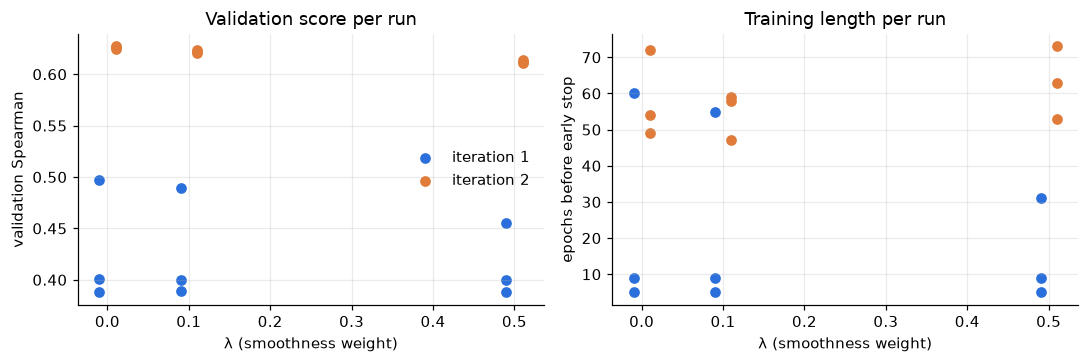

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for i, (it, g) in enumerate(grid.groupby("iteration")):
    axes[0].scatter(g["lambda"] + (i - 0.5) * 0.02, g.val_spearman, color=COLORS[i], label=f"iteration {it[-1]}")
    axes[1].scatter(g["lambda"] + (i - 0.5) * 0.02, g.epochs, color=COLORS[i])
axes[0].set(xlabel="λ (smoothness weight)", ylabel="validation Spearman", title="Validation score per run")
axes[1].set(xlabel="λ (smoothness weight)", ylabel="epochs before early stop", title="Training length per run")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading.** In iteration 1, early stopping with a patience of 10 epochs on a noisy validation
metric stopped some seeds within the first ten epochs, and its curve collapsed towards the mean.
Iteration 2 used a patience of 40 and the exact heuristic. Its three seeds agree closely.

## 4. Test evaluation, recomputed from the saved weights

For each version, `retrain._predictions` does the following:
- loads the bundle;
- rebuilds the test episodes from the database (windows, exact heuristic, teacher targets);
- embeds the windows with the bundle's own encoder copy;
- runs the BiLSTM.

`evaluation.evaluate` then compares the student, the heuristic alone and a constant curve with the
teacher score, using four metrics:
- **Spearman**: rank correlation of the curve with the teacher's;
- **top-20 %**: precision on the teacher's best fifth of the windows;
- **top-5**: overlap of the five best moments;
- **std**: the standard deviation of the curve. A flat curve gives Shorts nothing to choose from.

In [6]:
async def recompute(label):
    version, teacher, config, episodes, preds = await retrain._predictions(session_factory, label, "test")
    constant = (config.training or {}).get("train_target_mean", 0.5)
    report = evaluation.evaluate(
        [evaluation.EpisodeEval(e.upload_id, e.target, e.heuristic, e.llm, e.starts, *preds[e.upload_id])
         for e in episodes], constant)
    return report, episodes, preds


t0 = time.time()
reports, test_eps, test_preds = {}, {}, {}
for label in (I1, I2):
    reports[label], test_eps[label], test_preds[label] = await recompute(label)
print(f"recomputed both versions in {time.time() - t0:.0f} s on {settings.relevance_device}")

summary = pd.DataFrame({
    ("constant", ""): reports[I2]["summary"]["constant"],
    ("heuristic alone", ""): reports[I2]["summary"]["heuristic"],
    ("BiLSTM", "iteration 1"): reports[I1]["summary"]["bilstm"],
    ("BiLSTM", "iteration 2"): reports[I2]["summary"]["bilstm"],
}).T[["spearman", "top20_precision", "top5_overlap", "std", "spearman_llm_head"]]
summary

recomputed both versions in 34 s on cuda


spearman  top20_precision  top5_overlap  \
constant                        0.000            0.198         0.025   
heuristic alone                 0.545            0.478         0.275   
BiLSTM          iteration 1     0.396            0.390         0.125   
                iteration 2     0.652            0.575         0.375   

                                   std  spearman_llm_head  
constant                     5.960e-08                NaN  
heuristic alone              1.752e-01                NaN  
BiLSTM          iteration 1  3.376e-03              0.380  
                iteration 2  8.602e-02              0.408

**Check against the report (Table "Trained relevance model on the 8 test episodes") and against the
metrics stored at evaluation time.**

In [7]:
report_table = {  # model: (Spearman, top-20 %, top-5, std) as printed in the report
    ("heuristic", I2): (0.545, 0.478, 0.275, 0.175),
    ("bilstm", I1): (0.396, 0.390, 0.125, 0.003),
    ("bilstm", I2): (0.652, 0.575, 0.375, 0.086),
}
for (model_key, label), vals in report_table.items():
    got = reports[label]["summary"][model_key]
    for name, rep in zip(["spearman", "top20_precision", "top5_overlap", "std"], vals):
        print(compare(f"{model_key:9s} {label[-2:]} {name:15s}", got[name], rep, tol=0.0006))
for label in (I1, I2):
    stored = json.loads((settings.relevance_model_root / label / "metrics.json").read_text())["test"]["summary"]["bilstm"]
    print(compare(f"{label[-2:]} Spearman vs. metrics.json", reports[label]["summary"]["bilstm"]["spearman"],
                  stored["spearman"], tol=1e-6))
print(compare("i2 LLM head vs. teacher LLM component", reports[I2]["summary"]["bilstm"]["spearman_llm_head"], 0.41, tol=0.005))
print(compare("i1 LLM head vs. teacher LLM component", reports[I1]["summary"]["bilstm"]["spearman_llm_head"], 0.38, tol=0.005))

heuristic i2 spearman       : recomputed 0.5445 matches the report (0.5450)
heuristic i2 top20_precision: recomputed 0.4777 matches the report (0.4780)
heuristic i2 top5_overlap   : recomputed 0.2750 matches the report (0.2750)
heuristic i2 std            : recomputed 0.1752 matches the report (0.1750)
bilstm    i1 spearman       : recomputed 0.3960 matches the report (0.3960)
bilstm    i1 top20_precision: recomputed 0.3902 matches the report (0.3900)
bilstm    i1 top5_overlap   : recomputed 0.1250 matches the report (0.1250)
bilstm    i1 std            : recomputed 0.0034 matches the report (0.0030)
bilstm    i2 spearman       : recomputed 0.6522 matches the report (0.6520)
bilstm    i2 top20_precision: recomputed 0.5751 matches the report (0.5750)
bilstm    i2 top5_overlap   : recomputed 0.3750 matches the report (0.3750)
bilstm    i2 std            : recomputed 0.0860 matches the report (0.0860)
i1 Spearman vs. metrics.json: recomputed 0.3960 matches the report (0.3960)
i2 Spearman 

## 5. The offline gate and the per-episode picture

**Gate (decision 0024 §7):** the student's mean test Spearman must be above that of the heuristic
alone. Otherwise the cheaper heuristic would be just as good.

gate rule: BiLSTM mean Spearman vs the teacher > the heuristic alone's (0024 §7)
  bilstm-e5s-20261114-i1: BiLSTM 0.396 vs heuristic 0.545 -> FAIL
  bilstm-e5s-20261114-i2: BiLSTM 0.652 vs heuristic 0.545 -> PASS


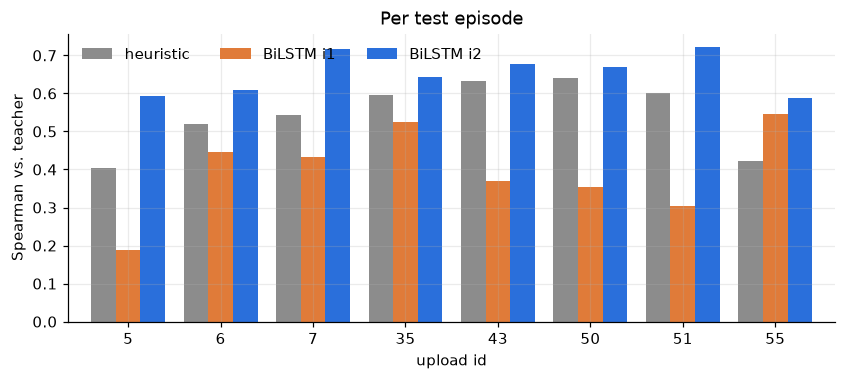

,heuristic,BiLSTM i1,BiLSTM i2,i2 LLM head
upload_id,,,,
5,0.403,0.189,0.594,0.551
6,0.519,0.446,0.609,0.317
7,0.544,0.433,0.717,0.467
35,0.596,0.526,0.644,0.325
43,0.632,0.369,0.677,0.410
50,0.640,0.353,0.669,0.168
51,0.601,0.304,0.721,0.518
55,0.422,0.547,0.587,0.509


In [8]:
gate = reports[I2]["gate"]
print(f"gate rule: {gate['rule']}")
for label in (I1, I2):
    g = reports[label]["gate"]
    print(f"  {label}: BiLSTM {g['bilstm_spearman']:.3f} vs heuristic {g['heuristic_spearman']:.3f} -> "
          f"{'PASS' if g['passed'] else 'FAIL'}")

per = pd.DataFrame([{"upload_id": e["upload_id"], "heuristic": e["heuristic"]["spearman"],
                     "BiLSTM i1": r1["bilstm"]["spearman"], "BiLSTM i2": e["bilstm"]["spearman"],
                     "i2 LLM head": e["bilstm"]["spearman_llm_head"]}
                    for e, r1 in zip(reports[I2]["per_episode"], reports[I1]["per_episode"])]).set_index("upload_id")
ax = per[["heuristic", "BiLSTM i1", "BiLSTM i2"]].plot.bar(figsize=(9, 3.4), color=[GREY, COLORS[1], COLORS[0]], width=0.8)
ax.set(ylabel="Spearman vs. teacher", title="Per test episode", xlabel="upload id")
ax.legend(frameon=False, ncol=3)
plt.xticks(rotation=0)
plt.show()
per.round(3)

## 6. What the curves look like

The teacher score, the student of each iteration, and the heuristic alone on one test episode.
Iteration 1's curve is almost flat: its standard deviation is 0.003. That is the collapse that
failed the gate.

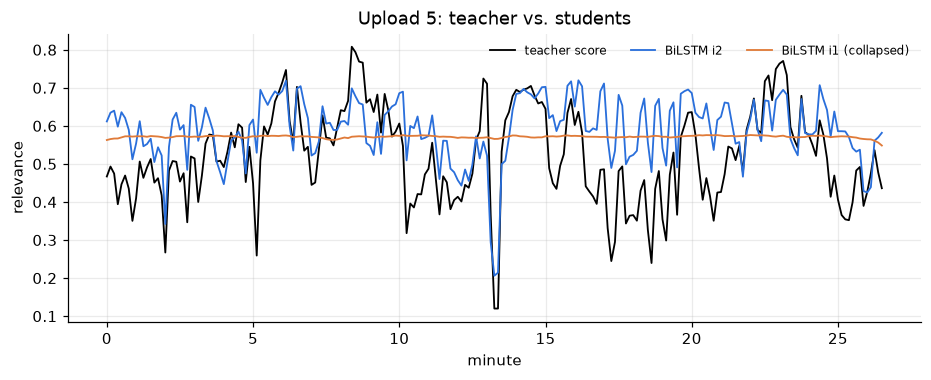

In [9]:
uid = 5
e2 = {e.upload_id: e for e in test_eps[I2]}[uid]
s1 = test_preds[I1][uid][2]
s2 = test_preds[I2][uid][2]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(e2.starts / 60, e2.target, color="black", lw=1.2, label="teacher score")
ax.plot(e2.starts / 60, s2, color=COLORS[0], lw=1.2, label="BiLSTM i2")
ax.plot(e2.starts / 60, s1, color=COLORS[1], lw=1.2, label="BiLSTM i1 (collapsed)")
ax.set(xlabel="minute", ylabel="relevance", title=f"Upload {uid}: teacher vs. students")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

## 7. Blind A/B and promotion

Passing the offline gate is not enough. `app.cli relevance ab-sheet` wrote a blind sheet: for five
test episodes, the top moments of the student and of the teacher, unlabelled and in random order.
The owner chose the better set per episode. The result is stored in `model_versions.metrics`. The
sheet itself contains transcript text and stays outside the repository.

In [10]:
ab = (await sql("select metrics -> 'ab' as ab from model_versions where version_label = :l", l=I2)).ab[0]
print(json.dumps({k: v for k, v in ab.items() if k not in ("answers", "per_episode")}, indent=1))
status = await retrain.promotion_status(session_factory, I2)
print("promotion status:", status)

{
 "ties": 0,
 "wins": 3,
 "losses": 2,
 "passed": true,
 "scored_at": "2026-11-14T11:55:39+00:00"
}


promotion status: {'label': 'bilstm-e5s-20261114-i2', 'live': 'bilstm-e5s-20261114-i2', 'offline_gate': True, 'ab': True, 'promotable': True, 'pseudo_labels': 19348}


## 8. Speed

The point of the student is speed. Below, one full test episode is scored with the deployed class
`bilstm.BiLSTMScorer`, the one the worker uses: encoder + BiLSTM + exact heuristic, without the
embedding cache. The report's figure (decision 0024: 1.0 s, plus a one-off bundle load of 2.0 s)
was measured the same way.

In [11]:
device = bilstm.resolve_device(settings.relevance_device)
t0 = time.time()
scorer = bilstm.BiLSTMScorer(bundle, device=device)  # cache_dir=None: embeddings computed afresh
load_s = time.time() - t0
scorer.score_windows(e2.windows[:8])  # warm-up on a few windows
timings = []
for _ in range(3):
    t0 = time.time()
    lang, scored = scorer.score_windows(e2.windows)
    timings.append(time.time() - t0)
print(f"upload {uid}: {len(scored)} windows ({e2.starts[-1] / 60:.0f} min, language {lang}) on {device}")
print(f"  bundle load {load_s:.1f} s; scoring {np.median(timings):.2f} s (median of 3 runs: "
      f"{', '.join(f'{t:.2f}' for t in timings)})")
assert np.allclose([s.score for s in scored], test_preds[I2][uid][2], atol=1e-4), "differs from the evaluation"
print("  the scores equal those of the evaluation above")

upload 5: 213 windows (26 min, language es) on cuda
  bundle load 1.5 s; scoring 0.23 s (median of 3 runs: 0.25, 0.23, 0.23)
  the scores equal those of the evaluation above


**Note on the number.** The run above is faster than the 1.0 s that the report gives for the
same episode. The model and its scores are identical; only the measurement conditions differ. The
report's figure was one run at M15 time, while here it is the median of three runs after a
warm-up. Either way, scoring takes about a second or less, against several minutes of LLM time for
the teacher (notebook 08).

## Summary

- Iteration 1 (two heads, patience 10) **failed** the gate: its curve collapsed to the mean.
- Iteration 2 (exact heuristic + LLM head, patience 40) **passed** the gate (0.652 vs. 0.545) and
  the blind A/B (3–2). It is the live version.
- The LLM head recovers part of the teacher's LLM judgement (Spearman 0.41). The teacher's own
  pass-to-pass agreement is 0.49 (notebook 02).
- Limitation: the second iteration was evaluated on the same test episodes as the first, so its
  test numbers are slightly optimistic (report, *Limitations of the Evaluation*).
- Rollback: `python -m app.cli models set-live relevance heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3`.